# Bean Leaf Disease Classification: End-to-End ML Pipeline

**Dataset:** [Beans](https://huggingface.co/datasets/AI-Lab-Makerere/beans) by the Makerere AI Lab (Uganda): smartphone photos of bean leaves taken in the field,
labelled as **angular leaf spot**, **bean rust** or **healthy**.

**Model:** MobileNetV2 (ImageNet weights) with transfer learning and fine-tuning, TensorFlow 2.16 / Keras 3.

This notebook imports all logic from `src/` so the notebook, the API and the retraining job use exactly the same code:

| Module | Role |
|---|---|
| `src/data_acquisition.py` | download the dataset into `data/train` and `data/test` |
| `src/preprocessing.py` | image loading, `tf.data` pipelines, augmentation, EDA features |
| `src/model.py` | build, train, evaluate, save and retrain the model |
| `src/prediction.py` | cached inference used by the API |

Sections: 1. Data acquisition · 2. EDA · 3. Preprocessing · 4. Model training · 5. Evaluation · 6. Prediction demo

In [1]:
import os, sys, json
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src.config import CLASSES, TRAIN_DIR, TEST_DIR, MODEL_PATH, H5_PATH
from src import data_acquisition, preprocessing as pp, model as model_lib, prediction

sns.set_theme(style="whitegrid")
PALETTE = {"angular_leaf_spot": "#d98c2b", "bean_rust": "#a8442c", "healthy": "#3b9a57"}
print("Repo root:", ROOT)

Repo root: C:\Users\PeggyDusenge\Desktop\U\MLOP-SUMMATIVE


## 1. Data acquisition

In [2]:
data_acquisition.download()          # skips the download if data/ is already populated
train_counts = pp.class_distribution(TRAIN_DIR)
test_counts = pp.class_distribution(TEST_DIR)
pd.DataFrame({"train (train+val)": train_counts, "test": test_counts}).assign(
    total=lambda d: d.sum(axis=1))

Dataset already present, skipping download (use --force to redo).


,train (train+val),test,total
angular_leaf_spot,389,43,432
bean_rust,393,43,436
healthy,385,42,427


The Hugging Face `train` (1,034) and `validation` (133) splits are merged into `data/train` (1,167 images);
a stratified-by-seed 15 % validation split is carved out at training time. The official `test` split (128 images) is
held out and used **only** for the final evaluation below.

## 2. Exploratory data analysis

### 2.1 Feature 1: class distribution

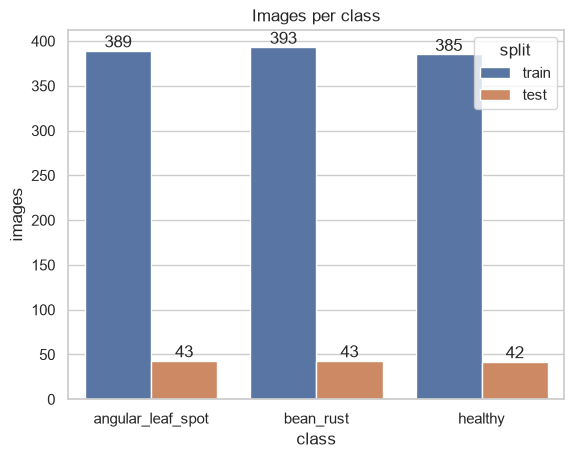

Imbalance ratio (largest / smallest train class): 1.021


In [3]:
dist = pd.DataFrame({"split": ["train"] * 3 + ["test"] * 3,
                     "class": CLASSES * 2,
                     "images": list(train_counts.values()) + list(test_counts.values())})
ax = sns.barplot(data=dist, x="class", y="images", hue="split")
for c in ax.containers: ax.bar_label(c)
ax.set_title("Images per class"); plt.show()
print(f"Imbalance ratio (largest / smallest train class): {max(train_counts.values()) / min(train_counts.values()):.3f}")

**What story does this tell?** The dataset is almost perfectly balanced: 385-393 training images per class (largest/smallest ratio 1.02) and 42-43 test images per class. That has two consequences. (1) The model has no prior incentive to favour one class, so any recall gap we see later comes from visual difficulty, not from class frequency. (2) Plain accuracy is a fair summary here, but we still report macro precision/recall/F1 because user uploads can unbalance the training set over time. If, say, farmers upload mostly rust images, the minority classes would start losing recall. That is why `src.model` passes inverse-frequency class weights to `fit` on every (re)training run.

### 2.2 Sample images per class

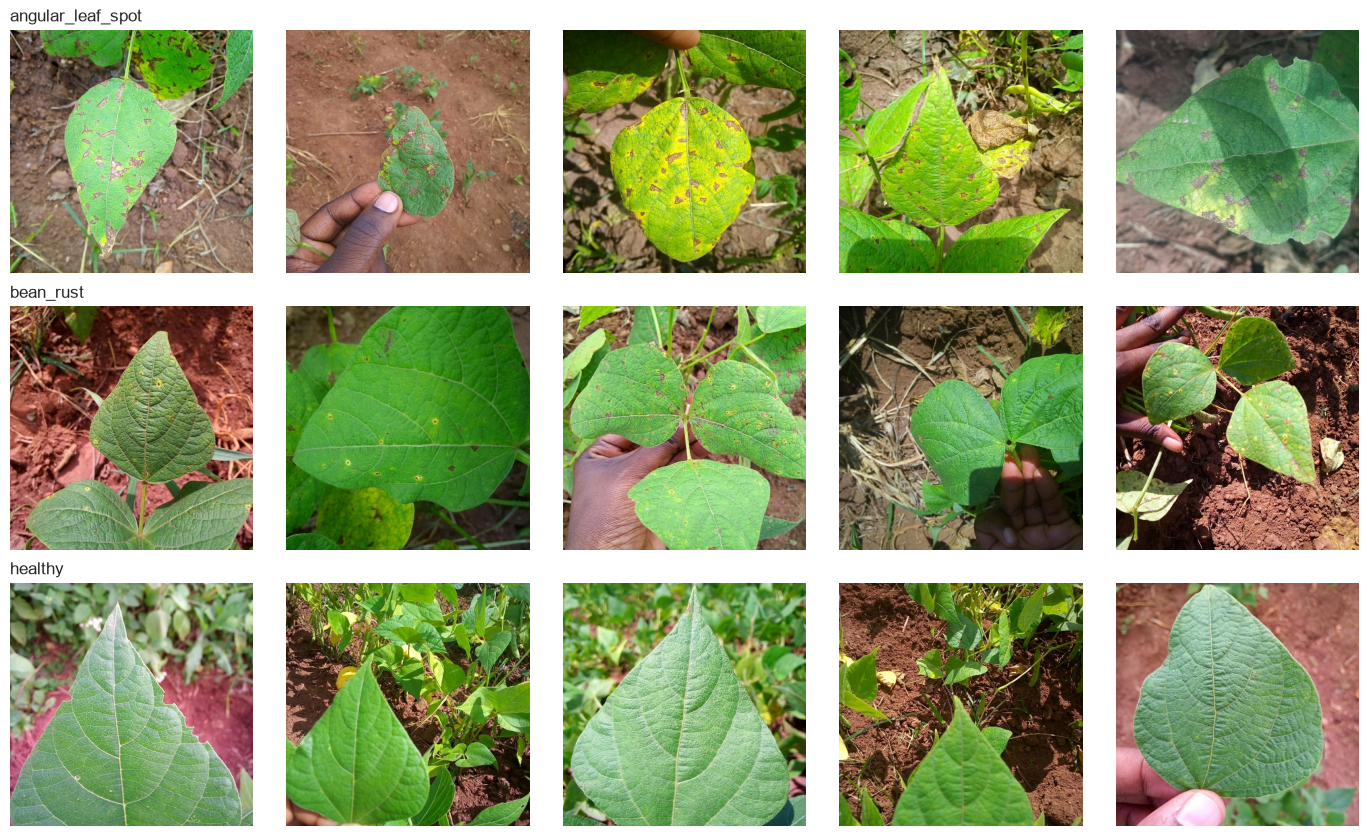

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
rng = np.random.default_rng(0)
for r, c in enumerate(CLASSES):
    files = pp.list_images(TRAIN_DIR, c)
    for k, f in enumerate(rng.choice(files, 5, replace=False)):
        axes[r, k].imshow(Image.open(f)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=12)
plt.tight_layout(); plt.show()

**What story does this tell?** Photos are taken in the field with a smartphone, often held in a hand, against soil, other leaves or sky. Leaf size, angle and background vary a lot, so the model must learn the *lesions*, not the framing. Angular leaf spot shows angular brown patches bounded by veins, often with yellowing. Bean rust shows many small round reddish-brown pustules, sometimes with yellow halos. Healthy leaves are uniformly green. Hands and soil appear in all three classes, which is good: they cannot act as a class shortcut.

### Per-image colour and lighting features
For each training image we compute (at 224x224): mean R, G, B; brightness (mean grey level); contrast (grey-level standard
deviation); mean hue and saturation (HSV). `pp.feature_table` is the same function that produces `docs/eda_stats.json` for the UI.

In [5]:
feats = pp.feature_table(TRAIN_DIR)
feats.groupby("label")[["mean_r", "mean_g", "mean_b", "hue", "saturation", "brightness", "contrast"]].agg(["mean", "std"]).round(2).T

label            angular_leaf_spot  bean_rust  healthy
mean_r     mean             128.38     121.42   120.68
           std               26.24      27.45    21.64
mean_g     mean             134.44     119.69   142.65
           std               22.11      20.98    21.83
mean_b     mean              73.69      78.69    85.96
           std               24.28      26.90    25.34
hue        mean              75.44      77.56    99.15
           std               37.73      32.82    26.07
saturation mean               0.52       0.47     0.49
           std                0.12       0.15     0.13
brightness mean             125.70     115.53   129.62
           std               20.24      21.37    18.71
contrast   mean              41.46      42.60    41.94
           std                9.76       8.96     7.96

### 2.3 Feature 2: colour (mean R, G, B and hue per class)

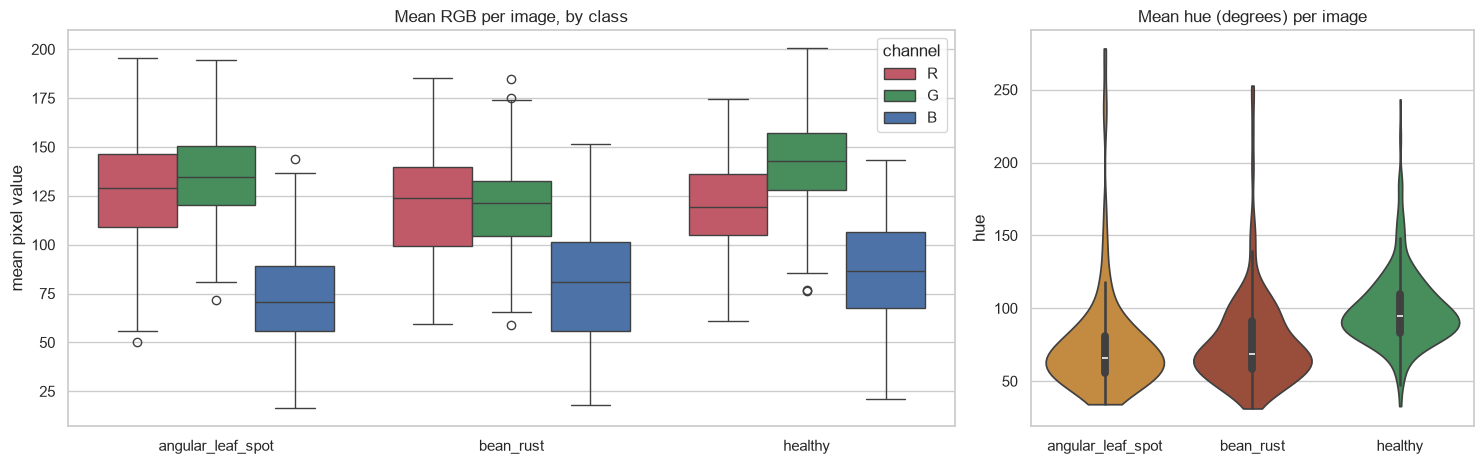

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 1]})
long = feats.melt(id_vars="label", value_vars=["mean_r", "mean_g", "mean_b"], var_name="channel", value_name="mean pixel value")
long["channel"] = long["channel"].str[-1].str.upper()
sns.boxplot(data=long, x="label", y="mean pixel value", hue="channel",
            palette={"R": "#d1495b", "G": "#3b9a57", "B": "#3d6fb6"}, ax=axes[0])
axes[0].set_title("Mean RGB per image, by class")
sns.violinplot(data=feats, x="label", y="hue", hue="label", palette=PALETTE, legend=False, ax=axes[1], cut=0)
axes[1].set_title("Mean hue (degrees) per image")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

**What story does this tell?** Colour carries real signal. Healthy leaves have the highest mean green (143 vs 134 for angular leaf spot and 120 for rust) and a clearly higher mean hue (about 99° vs 75-78° for the two diseases): diseased tissue turns brown/yellow, which moves the hue toward red/orange. Bean rust is the least green class, consistent with dense pustules covering the leaf; angular leaf spot keeps more green but has the highest red. Kruskal-Wallis tests confirm the class differences are highly significant for green (H=192) and hue (H=268). However, the boxes overlap heavily: a lightly infected leaf has almost the same average colour as a healthy one. Global colour therefore can't separate the classes on its own, and the CNN has to use local texture and lesion shape. This predicts that the hardest cases will be early-stage infections, which is exactly what the error analysis in section 5 shows.

### 2.4 Feature 3: brightness and contrast (lighting-bias check)

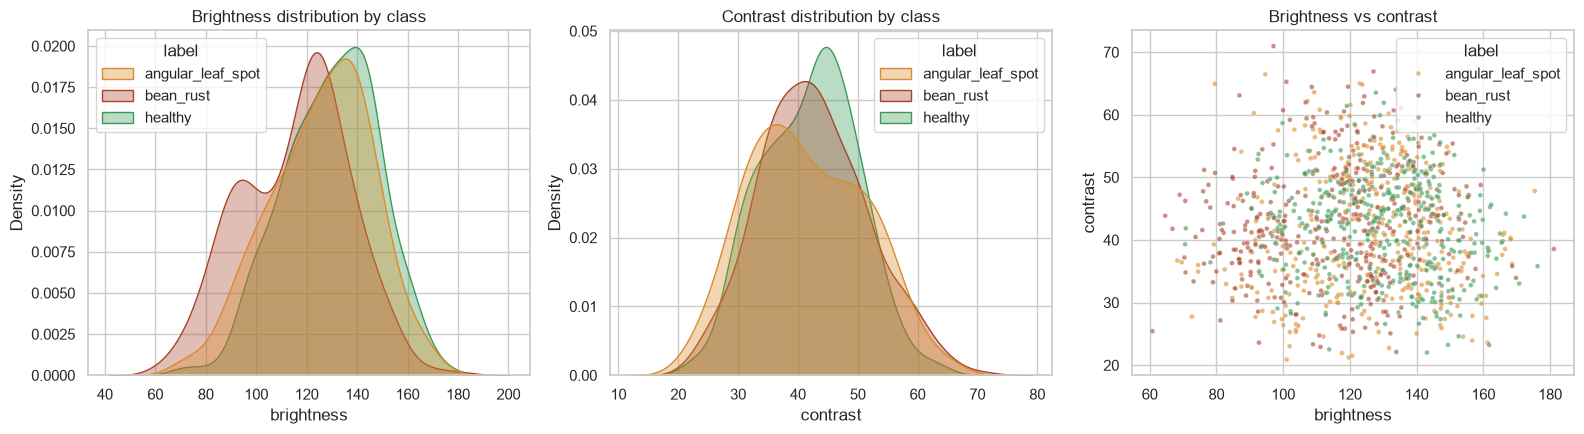

Kruskal-Wallis brightness: H=   87.9  p=8.07e-20
Kruskal-Wallis contrast  : H=    3.0  p=2.24e-01
Kruskal-Wallis mean_g    : H=  191.9  p=2.09e-42
Kruskal-Wallis hue       : H=  267.5  p=7.99e-59


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, f in zip(axes[:2], ["brightness", "contrast"]):
    sns.kdeplot(data=feats, x=f, hue="label", palette=PALETTE, fill=True, common_norm=False, alpha=.35, ax=ax)
    ax.set_title(f"{f.title()} distribution by class")
sns.scatterplot(data=feats, x="brightness", y="contrast", hue="label", palette=PALETTE, s=12, alpha=.6, ax=axes[2])
axes[2].set_title("Brightness vs contrast")
plt.tight_layout(); plt.show()

from scipy.stats import kruskal
for f in ["brightness", "contrast", "mean_g", "hue"]:
    groups = [feats.loc[feats.label == c, f] for c in CLASSES]
    print(f"Kruskal-Wallis {f:10s}: H={kruskal(*groups).statistic:7.1f}  p={kruskal(*groups).pvalue:.2e}")

**What story does this tell?** This is a check for *lighting bias*: if one class had been photographed in systematically brighter or higher-contrast conditions, a model could learn the lighting instead of the disease. **Contrast** is essentially identical across classes (means 41.5-42.6, Kruskal-Wallis p = 0.22, not significant), so there is no contrast shortcut. **Brightness** does differ significantly (rust about 116 vs 126-130 for the others), but the shift is half a standard deviation and the distributions overlap almost completely. The darker rust images are explained by the dark pustules themselves, not by camera settings. We conclude the data were collected under comparable field conditions. As extra insurance, training uses random-contrast augmentation, so small lighting differences are not a reliable cue for the model.

## 3. Preprocessing

* `tf.keras.utils.image_dataset_from_directory` reads `data/train/<class>/`, resizes to **224x224** and batches (32).
* 85 / 15 train / validation split with a fixed seed.
* **Augmentation** (inside the model, active only during training): random horizontal+vertical flips, rotation ±15 %, zoom ±15 %,
  contrast ±10 %. Leaves have no canonical orientation, and the contrast jitter is a guard against the mild lighting differences above.
* **Scaling** to MobileNetV2's expected [-1, 1] range is a `Rescaling(1/127.5, offset=-1)` layer **inside the model**, so the API
  sends raw 0-255 pixels and there is exactly one preprocessing path for training and serving.
* Inverse-frequency **class weights** are passed to `fit`, which matters after users upload unbalanced batches.

Found 1167 files belonging to 3 classes.


Using 992 files for training.


Found 1167 files belonging to 3 classes.


Using 175 files for validation.


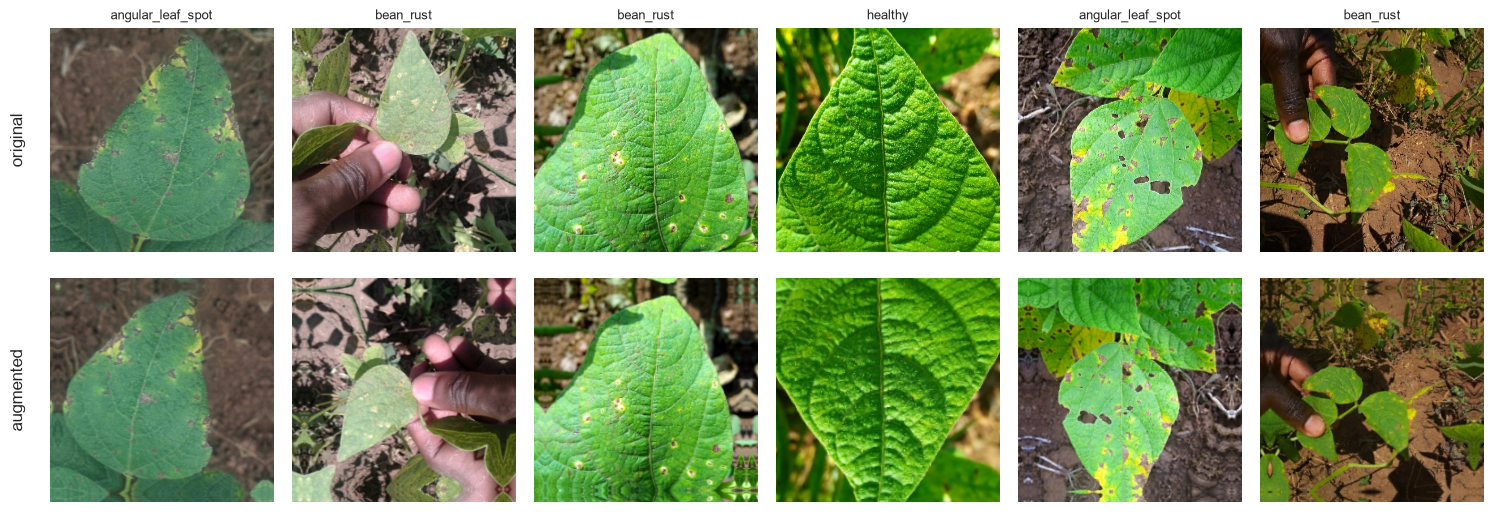

In [8]:
train_ds, val_ds = pp.make_datasets(TRAIN_DIR)
images, labels = next(iter(train_ds))
aug = pp.augmentation_layer()
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for k in range(6):
    axes[0, k].imshow(images[k].numpy().astype("uint8")); axes[0, k].set_title(CLASSES[int(labels[k])], fontsize=9)
    axes[1, k].imshow(np.clip(aug(images[k:k+1], training=True)[0].numpy(), 0, 255).astype("uint8"))
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].text(-40, 112, "original", rotation=90, va="center"); axes[1, 0].text(-40, 112, "augmented", rotation=90, va="center")
plt.tight_layout(); plt.show()

## 4. Model training

**Architecture:** input → augmentation → rescaling → **MobileNetV2 backbone** (ImageNet, layer named `backbone`) → global average pooling
→ dropout 0.3 → dense softmax (3).

**Two-stage training** (`src.model.train`):
1. *Head training:* backbone frozen, Adam lr 1e-3, up to 10 epochs.
2. *Fine-tuning:* the top ~54 backbone layers are unfrozen (`model.get_layer("backbone")`, BatchNorm kept frozen), Adam lr 1e-5, up to 10 epochs.

Both stages use early stopping on validation accuracy (patience 4, best weights restored).
Optimisation choices: transfer learning, data augmentation, dropout regularisation, early stopping, low fine-tuning learning rate and class weights.

Training takes about 10 minutes on a laptop CPU, so by default the notebook loads the saved model and its training history;
set `RUN_TRAINING = True` to retrain from scratch.

In [9]:
RUN_TRAINING = False
if RUN_TRAINING or not MODEL_PATH.exists():
    meta = model_lib.train(head_epochs=10, ft_epochs=10)
else:
    meta = model_lib.load_meta()
model = model_lib.load_model()
print(f"Model v{meta['version']} trained at {meta['trained_at']} ({meta.get('epochs_run')} epochs)")
print(f"Saved as {MODEL_PATH.name} and {H5_PATH.name}")
model.summary(line_length=100)

Model v1 trained at 2026-11-23T17:13:09.167763+00:00 (20 epochs)
Saved as bean_model.keras and bean_model.h5


Model: "bean_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ augmentation (Sequential)                  │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ rescale (Rescaling)                        │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backbone (Functional)                      │ (None, 7, 7, 1280)              │         2,257,984 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ gap (GlobalAveragePooling2D)               │ (None, 1280)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout (Dropout)                          │ (None, 1280)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ predictions (Dense)                        │ (None, 3)                       │             3,843 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 1,843,459 (7.03 MB)

 Non-trainable params: 418,368 (1.60 MB)

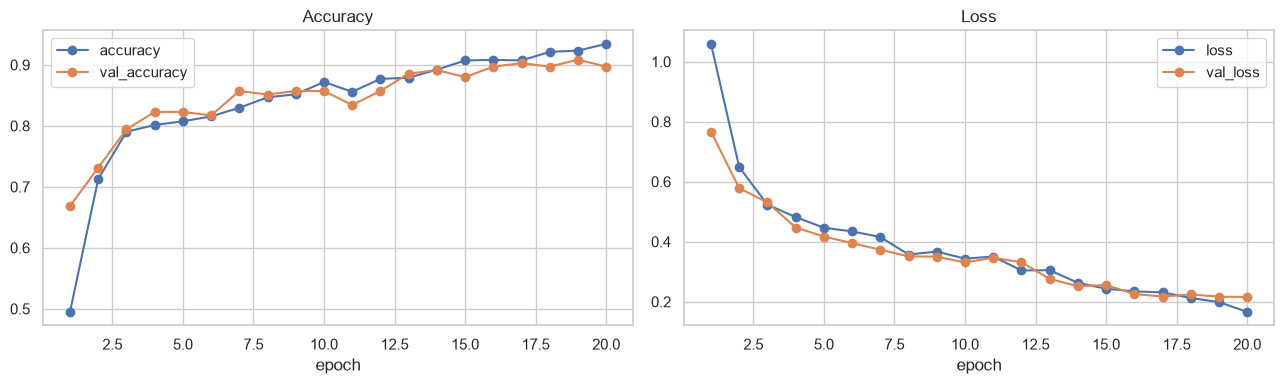

In [10]:
hist = pd.DataFrame(meta["history"]) if meta.get("kind") == "train" else None
if hist is not None:
    hist.index = hist.index + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hist[["accuracy", "val_accuracy"]].plot(ax=axes[0], marker="o", title="Accuracy")
    hist[["loss", "val_loss"]].plot(ax=axes[1], marker="o", title="Loss")
    for a in axes: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

**What story does this tell?** Validation accuracy rises steadily from 0.67 to about 0.86 during the 10 frozen-backbone epochs, then climbs to about 0.90-0.91 once the top of MobileNetV2 is fine-tuned at a 100x lower learning rate. Training and validation curves stay close: the final train accuracy (0.93, measured *with* augmentation active) is only a few points above validation, so augmentation, dropout and early stopping are keeping overfitting under control. The fine-tuning stage is what turns a decent ImageNet-feature classifier into a bean-specific one.

## 5. Evaluation on the held-out test set (128 images)

In [11]:
y_true, y_prob, paths = model_lib.predict_directory(model, TEST_DIR)
y_pred = y_prob.argmax(1)
metrics = model_lib.compute_metrics(y_true, y_prob)
pd.Series({k: metrics[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
          name="value (macro avg)").to_frame().round(4)

Found 128 files belonging to 3 classes.


,value (macro avg)
accuracy,0.9141
precision,0.9147
recall,0.9145
f1,0.9130
roc_auc,0.9890


In [12]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

                   precision    recall  f1-score   support

angular_leaf_spot      0.891     0.953     0.921        43
        bean_rust      0.921     0.814     0.864        43
          healthy      0.932     0.976     0.953        42

         accuracy                          0.914       128
        macro avg      0.915     0.915     0.913       128
     weighted avg      0.915     0.914     0.913       128



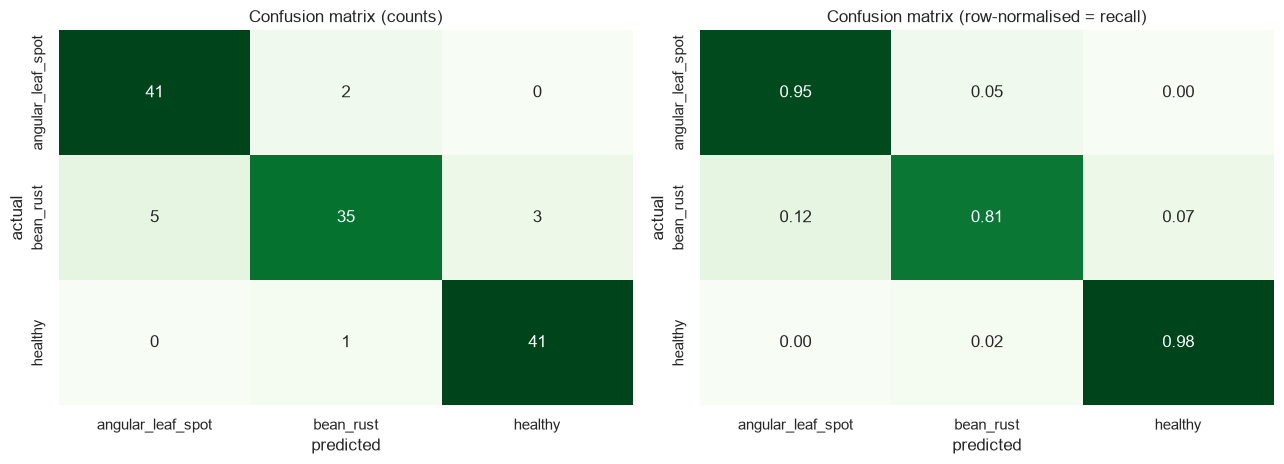

In [13]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False)
axes[0].set_title("Confusion matrix (counts)"); axes[1].set_title("Confusion matrix (row-normalised = recall)")
for a in axes: a.set_xlabel("predicted"); a.set_ylabel("actual")
plt.tight_layout(); plt.show()

**What story does this tell?** The model gets 117 of 128 test leaves right (accuracy 0.914, macro F1 0.913). The confusion is concentrated in **bean rust** (recall 0.81): 5 rust leaves were called angular leaf spot and 3 were called healthy. Healthy (recall 0.98) and angular leaf spot (recall 0.95) are recognised very reliably, and healthy and angular leaf spot are **never** confused with each other. From a farmer's point of view, the most costly error is a diseased leaf called *healthy* (no treatment applied); that happens 3 times out of 86 diseased test leaves (3.5 %), all of them rust. The two disease classes being confused with each other is less harmful, since both call for a closer look at the crop.

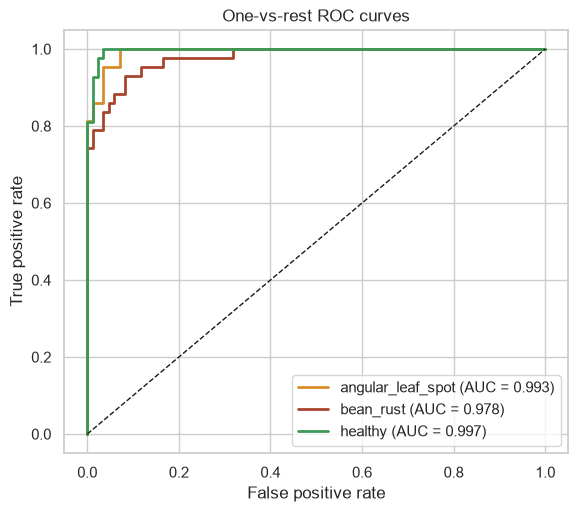

In [14]:
from sklearn.metrics import roc_curve, auc
plt.figure(figsize=(6.5, 5.5))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_true == i, y_prob[:, i])
    plt.plot(fpr, tpr, color=PALETTE[c], lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("One-vs-rest ROC curves")
plt.legend(loc="lower right"); plt.show()

**What story does this tell?** All three one-vs-rest AUCs are high (macro ROC-AUC 0.989), so the model's probability *ranking* is excellent even where its arg-max decision is wrong: the true class usually gets the second-highest probability rather than a near-zero one. Healthy is the easiest class to separate. Bean rust has the lowest AUC, matching its lower recall. Because the AUC is so high, a deployment could trade a little precision for recall on the disease classes by lowering their decision threshold, for example flagging any leaf with P(healthy) < 0.8 for inspection.

11 misclassified out of 128


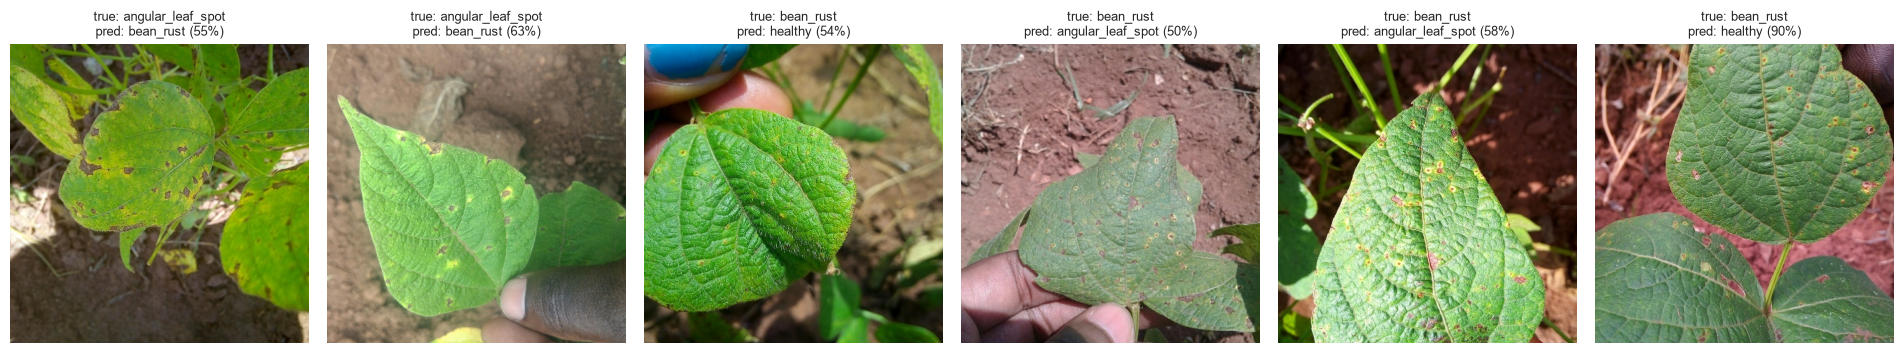

In [15]:
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified out of {len(y_true)}")
show = wrong[:6]
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(3.2 * len(show), 3.8), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(Image.open(paths[i])); ax.axis("off")
        ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({y_prob[i].max():.0%})", fontsize=9)
    plt.tight_layout(); plt.show()

**What story does this tell?** 11 of 128 test images are misclassified. Looking at them, most share a pattern: they are **early or sparse infections**. A few small rust pustules or spots sit on an otherwise green, healthy-looking leaf, so the leaf is still overwhelmingly green, which is exactly the overlap we saw in the colour EDA. Most errors are also *low-confidence* (50-63 %), so the model 'knows' it is unsure; the API's confidence score can be used to ask the user for a closer photo. The rust-vs-angular-leaf-spot mistakes happen where rust pustules are surrounded by yellow halos that resemble angular-spot lesions. The one high-confidence error (rust predicted healthy at 90 %) has only a handful of tiny pustules visible at full resolution, which become nearly invisible after resizing to 224x224. Remedies: more early-stage examples (the upload + retrain feature exists for this), higher input resolution, or tiling the leaf.

## 6. Prediction demo
`src.prediction.predict` is the exact function the FastAPI `/predict` endpoint calls. It accepts a path, raw bytes or a file object.

In [16]:
for c in CLASSES:
    f = pp.list_images(TEST_DIR, c)[3]
    res = prediction.predict(f)
    print(f"{f.name:22s} actual={c:18s} predicted={res['label']:18s} confidence={res['confidence']:.3f}")
    print("   ", {k: round(v, 3) for k, v in res["probabilities"].items()})

test_00003.jpg         actual=angular_leaf_spot  predicted=angular_leaf_spot  confidence=0.993
    {'angular_leaf_spot': 0.993, 'bean_rust': 0.007, 'healthy': 0.0}


test_00046.jpg         actual=bean_rust          predicted=bean_rust          confidence=0.931
    {'angular_leaf_spot': 0.0, 'bean_rust': 0.931, 'healthy': 0.068}


test_00089.jpg         actual=healthy            predicted=healthy            confidence=0.998
    {'angular_leaf_spot': 0.0, 'bean_rust': 0.002, 'healthy': 0.998}


## Conclusions
* **Data:** 1,295 field photos, balanced across 3 classes, with no lighting bias; colour separates healthy from diseased on average, but texture is needed for individual leaves.
* **Model:** MobileNetV2 transfer learning plus fine-tuning reaches **accuracy 0.914, macro precision 0.915, recall 0.915, F1 0.913 and ROC-AUC 0.989** on the held-out test set, from a 9 MB `.h5` model that runs on CPU.
* **Weakness:** early-stage bean rust (recall 0.81). Most of these errors are low-confidence, and they can be fixed with more data through the pipeline's upload-and-retrain loop.
* The same `src/` code powers this notebook, the FastAPI service (`/predict`, `/upload`, `/retrain`) and the retraining job, so the results here are what the deployed system serves.